# Program 3: Bank Customer Churn Prediction using Neural Network

### Problem Statement:
Given a bank customer, build a neural network-based classifier that can determine whether they will leave (churn) or not in the next 6 months.

### Dataset:
 (10,000 samples, 14 features)

### Steps:
1. Read the dataset.
2. Distinguish the feature and target set and divide the dataset into training and test sets.
3. Normalize the train and test data.
4. Initialize and build the model. Identify points of improvement and implement changes.
5. Print the accuracy score and confusion matrix.

In [1]:
import os
import warnings

warnings.filterwarnings('ignore')
os.environ.setdefault('KERAS_BACKEND', 'torch')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

try:
    import keras
    from keras.models import Sequential
    from keras.layers import Dense, Dropout
except ImportError:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Dropout

%matplotlib inline

In [2]:
# Step 1: Read the Dataset
df = pd.read_csv('Churn_Modelling.csv')
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Step 2: Distinguish Features and Target, Encode Categorical, Train-Test Split
df_clean = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], errors='ignore')

le_geo = LabelEncoder()
le_gender = LabelEncoder()
df_clean['Geography'] = le_geo.fit_transform(df_clean['Geography'])
df_clean['Gender'] = le_gender.fit_transform(df_clean['Gender'])

X = df_clean.drop(columns=['Exited'])
y = df_clean['Exited']

print(f"Features ({len(X.columns)}): {list(X.columns)}")
print(f"Class Distribution: Stayed (0) = {(y == 0).sum()}, Churned (1) = {(y == 1).sum()}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training Samples: {X_train.shape[0]}, Testing Samples: {X_test.shape[0]}")

Features (10): ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Class Distribution: Stayed (0) = 7963, Churned (1) = 2037
Training Samples: 8000, Testing Samples: 2000


In [4]:
# Step 3: Normalize Train and Test Data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("StandardScaler normalization applied successfully.")

StandardScaler normalization applied successfully.


In [5]:
# Step 4: Initialize and Build the Neural Network Model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# Train model
history = model.fit(
    X_train_scaled, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    verbose=0
)

print("\nTraining completed successfully (30 epochs).")
print(f"Final Training Accuracy  : {history.history['accuracy'][-1]:.4f}")
print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼─────────────────────

Accuracy Score: 0.8625 (86.25%)

Confusion Matrix:
  Stayed (0)  -> Correct: 1535, Misclassified: 72
  Churned (1) -> Correct: 190, Misclassified: 203

Classification Report:
              precision    recall  f1-score   support

  Stayed (0)       0.88      0.96      0.92      1607
 Churned (1)       0.73      0.48      0.58       393

    accuracy                           0.86      2000
   macro avg       0.80      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



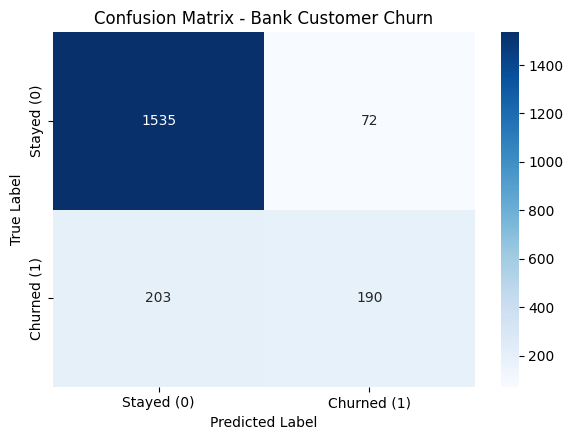

In [6]:
# Step 5: Evaluate the Model (Accuracy Score and Confusion Matrix)
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy Score: {acc:.4f} ({acc*100:.2f}%)\n")
print("Confusion Matrix:")
print(f"  Stayed (0)  -> Correct: {cm[0][0]}, Misclassified: {cm[0][1]}")
print(f"  Churned (1) -> Correct: {cm[1][1]}, Misclassified: {cm[1][0]}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Stayed (0)', 'Churned (1)']))

# Confusion Matrix Heatmap
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stayed (0)', 'Churned (1)'],
            yticklabels=['Stayed (0)', 'Churned (1)'])
plt.title('Confusion Matrix - Bank Customer Churn')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()